In [2]:
import pandas as pd
import numpy as np

# Create monthly sales data
dates = pd.date_range(
    start="2024-01-01",
    periods=24,
    freq="MS"
)

sales = [
    12000, 13500, 12800, 14500, 15000, 16000,
    15500, 17000, 18000, 17500, 19500, 22000,
    20000, 21500, 21000, 23000, 24000, 25000,
    24500, 26000, 27500, 27000, 29000, 32000
]

df = pd.DataFrame({
    "Date": dates,
    "Sales": sales
})

# Introduce a missing value for cleaning practice
df.loc[5, "Sales"] = np.nan

# Save as a CSV database file
df.to_csv("sales_data.csv", index=False)

print("Sales database created successfully!")
print(df.head(10))

Sales database created successfully!
        Date    Sales
0 2024-01-01  12000.0
1 2024-02-01  13500.0
2 2024-03-01  12800.0
3 2024-04-01  14500.0
4 2024-05-01  15000.0
5 2024-06-01      NaN
6 2024-07-01  15500.0
7 2024-08-01  17000.0
8 2024-09-01  18000.0
9 2024-10-01  17500.0


In [3]:
import pandas as pd

df = pd.read_csv("sales_data.csv")

print("Dataset loaded successfully!")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

Dataset loaded successfully!
         Date    Sales
0  2024-01-01  12000.0
1  2024-02-01  13500.0
2  2024-03-01  12800.0
3  2024-04-01  14500.0
4  2024-05-01  15000.0

Dataset shape: (24, 2)

Column names: ['Date', 'Sales']

Data types:
Date         str
Sales    float64
dtype: object


In [4]:
# Convert Date column into date format
df["Date"] = pd.to_datetime(df["Date"])

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing sales using interpolation
df["Sales"] = df["Sales"].interpolate()

# Remove duplicate rows
df = df.drop_duplicates()

# Sort by date
df = df.sort_values("Date").reset_index(drop=True)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned sales dataset:")
print(df.head(10))

Missing values before cleaning:
Date     0
Sales    1
dtype: int64

Missing values after cleaning:
Date     0
Sales    0
dtype: int64

Cleaned sales dataset:
        Date    Sales
0 2024-01-01  12000.0
1 2024-02-01  13500.0
2 2024-03-01  12800.0
3 2024-04-01  14500.0
4 2024-05-01  15000.0
5 2024-06-01  15250.0
6 2024-07-01  15500.0
7 2024-08-01  17000.0
8 2024-09-01  18000.0
9 2024-10-01  17500.0


In [5]:
from scipy import stats

# Calculate descriptive statistics
print("Mean sales:", round(df["Sales"].mean(), 2))
print("Median sales:", round(df["Sales"].median(), 2))
print("Standard deviation:", round(df["Sales"].std(), 2))

# Create a numerical time variable
df["Month_Number"] = np.arange(1, len(df) + 1)

# Analyze the relationship between time and sales
result = stats.linregress(
    df["Month_Number"],
    df["Sales"]
)

print("\nSales trend analysis")
print("Slope:", round(result.slope, 2))
print("Correlation:", round(result.rvalue, 3))
print("P-value:", round(result.pvalue, 4))

Mean sales: 20543.75
Median sales: 20500.0
Standard deviation: 5565.06

Sales trend analysis
Slope: 776.33
Correlation: 0.986
P-value: 0.0


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use month number as the input feature
X = df[["Month_Number"]]
y = df["Sales"]

# Keep the last 4 months for testing
X_train = X.iloc[:-4]
X_test = X.iloc[-4:]
y_train = y.iloc[:-4]
y_test = y.iloc[-4:]

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict test sales
test_predictions = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

print("Model trained successfully!")
print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))

comparison = pd.DataFrame({
    "Month": df["Date"].iloc[-4:].dt.strftime("%b %Y").values,
    "Actual Sales": y_test.values.round(2),
    "Predicted Sales": test_predictions.round(2)
})

print("\nActual vs Predicted Sales:")
print(comparison.to_string(index=False))

Model trained successfully!
Mean Absolute Error: 1376.8
Root Mean Squared Error: 1783.59

Actual vs Predicted Sales:
   Month  Actual Sales  Predicted Sales
Sep 2025       27500.0         26537.37
Oct 2025       27000.0         27266.88
Nov 2025       29000.0         27996.39
Dec 2025       32000.0         28725.90


In [8]:
# Retrain using all historical data
model.fit(X, y)

# Create future month numbers with the same column name
future_months = pd.DataFrame({
    "Month_Number": np.arange(
        len(df) + 1,
        len(df) + 7
    )
})

# Predict future sales
future_sales = model.predict(future_months)

# Create future dates
future_dates = pd.date_range(
    start=df["Date"].iloc[-1] + pd.offsets.MonthBegin(1),
    periods=6,
    freq="MS"
)

# Display forecast
forecast = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Sales": future_sales.round(2)
})

print("Next 6 Months Sales Forecast")
print(forecast.to_string(index=False))

Next 6 Months Sales Forecast
      Date  Predicted_Sales
2026-01-01         30247.83
2026-02-01         31024.15
2026-03-01         31800.48
2026-04-01         32576.80
2026-05-01         33353.13
2026-06-01         34129.46


In [9]:
print("SALES FORECAST TABLE")
display(forecast)

SALES FORECAST TABLE


,Date,Predicted_Sales
0,2026-01-01,30247.83
1,2026-02-01,31024.15
2,2026-03-01,31800.48
3,2026-04-01,32576.80
4,2026-05-01,33353.13
5,2026-06-01,34129.46


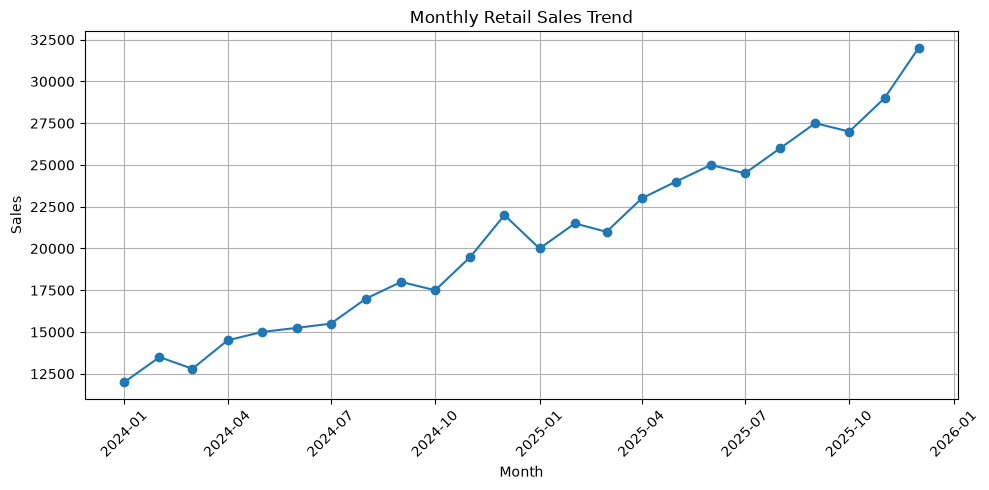

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Sales"], marker="o")

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

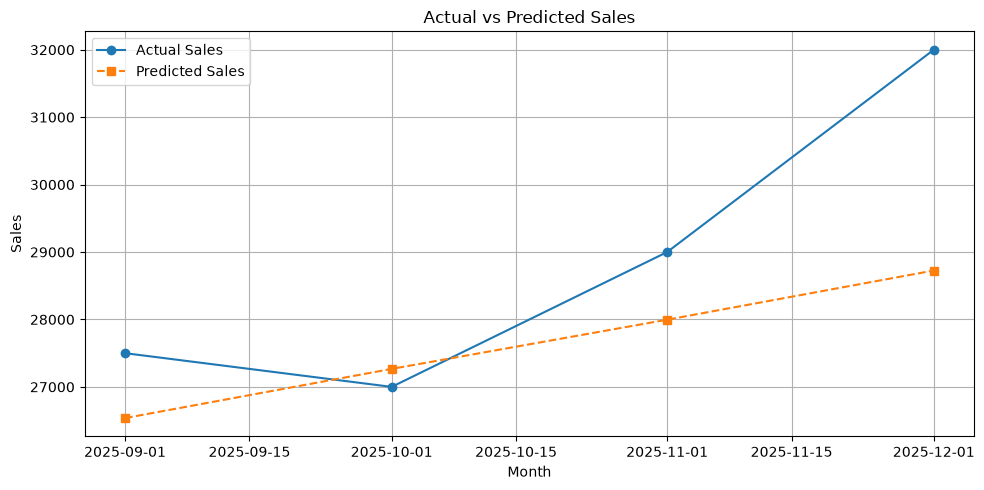

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    df["Date"].iloc[-4:],
    y_test.values,
    marker="o",
    label="Actual Sales"
)

plt.plot(
    df["Date"].iloc[-4:],
    test_predictions,
    marker="s",
    linestyle="--",
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

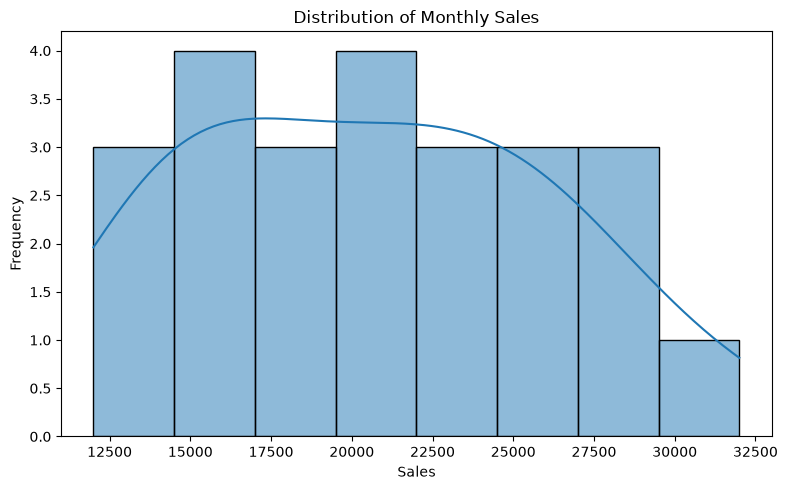

In [12]:
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Sales",
    bins=8,
    kde=True
)

plt.title("Distribution of Monthly Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

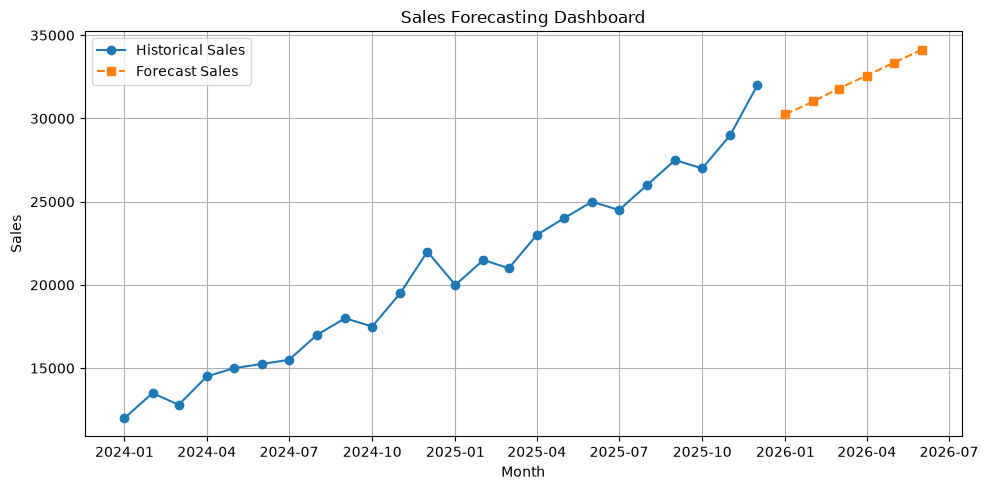

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(
    df["Date"],
    df["Sales"],
    marker="o",
    label="Historical Sales"
)

plt.plot(
    forecast["Date"],
    forecast["Predicted_Sales"],
    marker="s",
    linestyle="--",
    label="Forecast Sales"
)

plt.title("Sales Forecasting Dashboard")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
print("DESCRIPTIVE STATISTICS")
display(df[["Sales"]].describe())

DESCRIPTIVE STATISTICS


,Sales
count,24.000000
mean,20543.750000
std,5565.056203
min,12000.000000
25%,15437.500000
50%,20500.000000
75%,24625.000000
max,32000.000000


In [15]:
evaluation = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "Correlation with Time"
    ],
    "Value": [
        round(mae, 2),
        round(rmse, 2),
        round(result.rvalue, 3)
    ]
})

print("MODEL EVALUATION SUMMARY")
display(evaluation)

MODEL EVALUATION SUMMARY


,Metric,Value
0,Mean Absolute Error (MAE),1376.800
1,Root Mean Squared Error (RMSE),1783.590
2,Correlation with Time,0.986


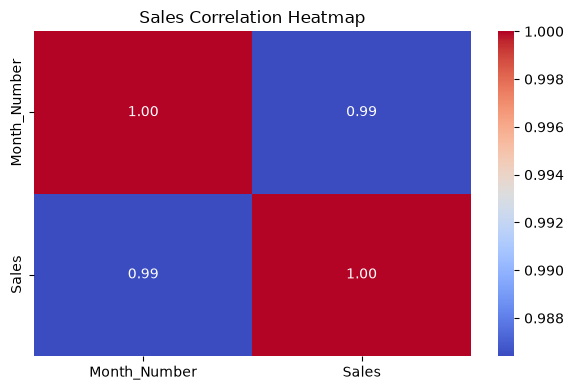

In [16]:
plt.figure(figsize=(6, 4))

correlation = df[["Month_Number", "Sales"]].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Sales Correlation Heatmap")
plt.tight_layout()
plt.show()

In [17]:
df.to_csv("cleaned_sales_data.csv", index=False)
forecast.to_csv("sales_forecast.csv", index=False)
comparison.to_csv("sales_comparison.csv", index=False)
evaluation.to_csv("sales_evaluation.csv", index=False)

print("All output files saved successfully!")

All output files saved successfully!
